# Generate a general platemap figure for the validation plates

All five validation plates share the same well layout: the controls and the wells for each compound are in the same positions on every plate, and only the compound identities change.
This figure shows that shared layout, with the three compounds on each plate labeled as compound slots A, B, and C.

## Import libraries

In [1]:
suppressPackageStartupMessages(library(dplyr))
suppressPackageStartupMessages(library(ggplot2))
suppressPackageStartupMessages(library(platetools))


Warning message:
“package ‘ggplot2’ was built under R version 4.2.3”
Warning message:
“package ‘platetools’ was built under R version 4.2.3”


## Set paths

In [ ]:
# directory for fig to be outputted
output_dir <- file.path("./platemap_fig")

# Create the output directory if it doesn't exist
if (!dir.exists(output_dir)) {
  dir.create(output_dir, recursive = TRUE)
}

# per-plate platemap files
platemap_files <- list.files(
    "./platemaps",
    pattern = "_platemap\\.csv$",
    full.names = TRUE
)
print(platemap_files)

# path for the general platemap figure
output_fig <- file.path(output_dir, "example_platemap.png")


[1] "./platemaps/CARD-CelIns-CX7_261030160001_platemap.csv"
[2] "./platemaps/CARD-CelIns-CX7_261031160001_platemap.csv"
[3] "./platemaps/CARD-CelIns-CX7_261101160003_platemap.csv"
[4] "./platemaps/CARD-CelIns-CX7_261102080001_platemap.csv"
[5] "./platemaps/CARD-CelIns-CX7_261102150001_platemap.csv"


## Load in platemap files and label the compound slots

Within each plate, compounds are given slot letters (A, B, C) in the order they first appear in the platemap (row by row).

In [ ]:
platemap_df <- platemap_files %>%
    lapply(readr::read_csv, col_types = readr::cols(.default = "c")) %>%
    dplyr::bind_rows() %>%
    dplyr::group_by(plate_barcode) %>%
    dplyr::mutate(
        compound_slot = match(treatment, unique(treatment[treatment != "DMSO"])),
        layout_group = dplyr::case_when(
            treatment == "DMSO" & cell_type == "failing" ~ "DMSO (failing)",
            treatment == "DMSO" & cell_type == "nonfailing" ~ "DMSO (non-failing)",
            TRUE ~ paste("Compound", LETTERS[compound_slot])
        )
    ) %>%
    dplyr::ungroup()

print(dim(platemap_df))

# Check that every plate has the same layout so one figure represents all plates
layout_per_plate <- platemap_df %>%
    dplyr::arrange(well_position) %>%
    dplyr::group_by(plate_barcode) %>%
    dplyr::summarise(
        layout = paste(well_position, cell_type, layout_group, collapse = ";")
    )
stopifnot(dplyr::n_distinct(layout_per_plate$layout) == 1)

# Show which compound fills each slot on each plate
platemap_df %>%
    dplyr::filter(treatment != "DMSO") %>%
    dplyr::distinct(plate_number, plate_barcode, layout_group, treatment) %>%
    tidyr::pivot_wider(names_from = layout_group, values_from = treatment) %>%
    dplyr::arrange(as.integer(plate_number))


[1] 300  11


plate_barcode,plate_number,Compound A,Compound B,Compound C
<chr>,<chr>,<chr>,<chr>,<chr>
CARD-CelIns-CX7_261030160001,1,K310,K543,K278
CARD-CelIns-CX7_261031160001,2,K756,K020,K845
CARD-CelIns-CX7_261101160003,3,K463,K208,K779
CARD-CelIns-CX7_261102080001,4,K221,K318,K645
CARD-CelIns-CX7_261102150001,5,K504,K687,K191


## Create the general platemap and save the figure

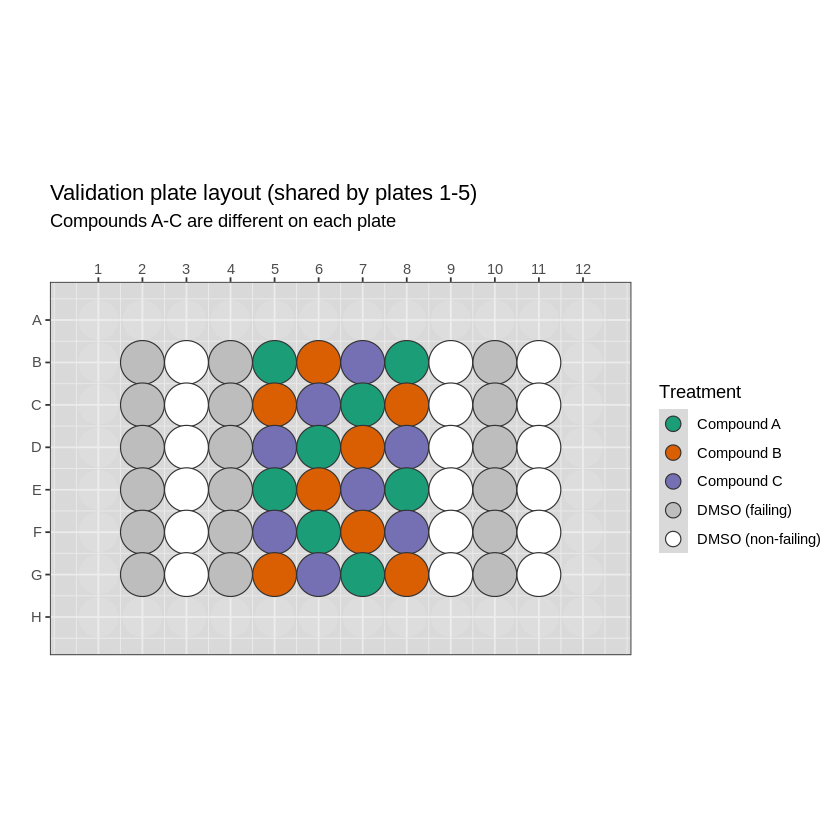

In [4]:
# Use one plate for the layout (all plates share it, checked above)
layout_df <- platemap_df %>%
    dplyr::filter(plate_barcode == dplyr::first(plate_barcode))

layout_colors <- c(
    "Compound A" = "#1b9e77",
    "Compound B" = "#d95f02",
    "Compound C" = "#7570b3",
    "DMSO (failing)" = "#bdbdbd",
    "DMSO (non-failing)" = "#ffffff"
)

platemap_gg <-
    platetools::raw_map(
        data = layout_df$layout_group,
        well = layout_df$well_position,
        plate = 96,
        size = 12
    ) +
    ggplot2::scale_fill_manual(
        name = "Treatment",
        values = layout_colors,
        guide = ggplot2::guide_legend(override.aes = list(size = 4))
    ) +
    ggplot2::labs(
        title = "Validation plate layout (shared by plates 1-5)",
        subtitle = "Compounds A-C are different on each plate"
    ) +
    ggplot2::theme(
        panel.background = ggplot2::element_rect(fill = "grey85", color = NA),
        plot.background = ggplot2::element_rect(fill = "white", color = NA)
    )

ggsave(
    output_fig,
    platemap_gg,
    dpi = 500,
    height = 4.5,
    width = 9
)

platemap_gg
